{'topic': '猫咪', 'poem': '《咏猫》\n眸如翡翠尾如鞭，飞檐走壁赛虎仙。\n轻扑缓跃无声息，一啸惊飞梁上燕。\n\n注：我的仿写创作思路是抓住猫的灵动与神秘特质。首句以翡翠喻瞳、鞭喻尾，凸显其优雅形态；次句“赛虎仙”暗藏猫科动物的野性基因。后两句通过扑跃动态与惊燕长啸的对比，展现其静如处子动如脱兔的特性，最终以“惊飞梁上燕”的意象收束，留有余韵。', 'joke': '有一只猫，它非常喜欢玩电脑。\n\n有一天，它的主人发现它坐在电脑前，一脸严肃地盯着屏幕。\n\n主人问：“你在干什么？”\n\n猫咪头也不回地说：“我在上网。”\n\n主人凑近一看，屏幕上是一个购物网站，购物车里装满了各种口味的猫罐头。\n\n主人惊讶地问：“你哪来的钱付款？”\n\n猫咪淡定地伸出爪子，指了指屏幕上的一个按钮，上面写着：\n\n**“货到付款（COD）”**\n\n主人：“……那你知道货到了要付钱吗？”\n\n猫咪舔了舔爪子，说：“没关系，收货人写的是你的名字。” 😼'}


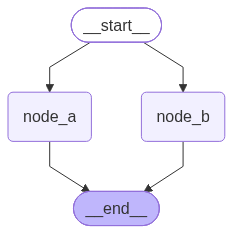

In [1]:
'''
静态节点：节点的下游候选节点 在图编译阶段就完全确定，只是运行时根据条件选择哪条边执行。
特点：
下游节点集合固定，数量、目标在编译时确定
运行时可选择一个或多个下游目标
可以用来做条件分支，但不生成新的节点

并行节点是最简单的静态分支形式。
当多个节点都从同一个上游节点触发时，它们会在同一个超步被激活。

- 这里的“并行”主要指**调度语义上的并行**；两个节点之间没有先后依赖；
- 它们的输出会在当前**超步**执行完成后统一合并到状态中；
- 如果两个节点写入同一个状态字段，则该字段通常需要配置合适的 **`Reducer`**，否则可能出现状态更新冲突，抛出 **`InvalidUpdateError`** 异常
'''

from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_deepseek import ChatDeepSeek
from langchain.messages import HumanMessage

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    ).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    ).content
    return {
        "joke": joke
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")

builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
res = graph.invoke({"topic": "猫咪"})
print(res)

from IPython.display import display

display(graph)




============================== -> poem <- ==============================
{'topic': '布偶猫', 'content_type': 'poem', 'poem': '《布偶猫》\n蓝瞳玉雪卧芸窗，尾扫流云影自双。\n忽跃案头翻墨卷，梅花印上读书缸。\n\n注：我的创作思路是抓住布偶猫蓝眼、长毛、温顺的品种特征，通过“玉雪”喻其毛色，“蓝瞳”点其眼瞳。后两句以动态描写展现其顽皮天性，用“梅花印”既指猫爪形状，又暗合传统文人雅趣，使全诗在工整格律中透出生活情趣。'}
============================== -> joke <- ==============================
{'topic': '布偶猫', 'content_type': 'joke', 'joke': '一只布偶猫走进酒吧，往吧台上一趴，对酒保说：\n\n“给我来一杯牛奶，不加冰。”\n\n酒保端来牛奶，好奇地问：“你怎么这么软绵绵的，像一团棉花糖？”\n\n布偶猫叹了口气：“唉，没办法，我天生就是‘布’偶嘛——布做的，能不软吗？”\n\n酒保沉默了三秒，然后默默把吧台上的“请勿抚摸宠物”牌子翻了个面，背面写着：“摸了就得负责。”'}
============================== -> illegal <- ==============================
{'topic': '布偶猫', 'content_type': 'illegal'}


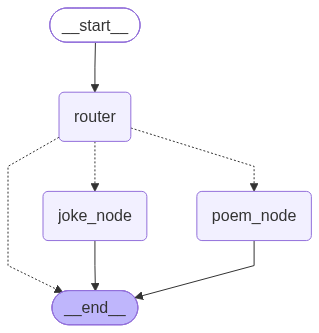

In [1]:
from typing import TypedDict, Literal
from langgraph.types import Command
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: Literal["poem", "joke"]
    poem: str
    joke: str

'''可以通过 Command(goto=...) 在节点内部实现条件分支。
与 add_conditional_edges() 相比，Command 更适合“状态更新”和“控制流跳转”需要放在同一个节点返回值中的场景。'''
def router(state: OverAllState) -> Command[Literal["poem_node", "joke_node", END]]:
    content_type = state["content_type"]
    if content_type == "poem":
        return Command (
            goto="poem_node"
        )
    elif content_type == "joke":
        return Command (
            goto="joke_node"
        )
    return Command (
        goto=END
    )

def poem_node(state: OverAllState) -> OverAllState:
    topic = state["topic"]
    prompt = f"请生成一首关于 {topic} 的七言绝句"
    poem = model.invoke([HumanMessage(prompt)]).content

    return {
        "poem": poem
    }

def joke_node(state: OverAllState) -> OverAllState:
    topic = state["topic"]
    prompt = f"请生成一个关于 {topic} 的冷笑话"
    joke = model.invoke([HumanMessage(prompt)]).content

    return {
        "joke": joke
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("router", router)
builder.add_node("poem_node", poem_node)
builder.add_node("joke_node", joke_node)
builder.add_edge(START, "router")
builder.add_edge("poem_node", END)
builder.add_edge("joke_node", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶猫", "content_type": "poem"})
joke_res = graph.invoke({"topic": "布偶猫", "content_type": "joke"})

# 这里故意传入一个不符合 Literal["poem", "joke"] 的值，
# 用来观察运行时兜底分支。
# 注意：Literal 主要服务于静态类型检查，
# 默认不会在 Python 运行时阻止非法值传入。
illegal_res = graph.invoke({
    "topic": "布偶猫",
    "content_type": "illegal"
})

print('=' * 30, '-> poem <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke <-', '=' * 30)
print(joke_res)
print('=' * 30, '-> illegal <-', '=' * 30)
print(illegal_res)

from IPython.display import display
display(graph)